# DS-A3 — Regression Baseline and Diagnostics
## Predicting adult Red Knot sex from morphometric data

### Research question
How accurately can the sex of adult Red Knots
(*Calidris canutus canutus*) be predicted using morphometric data?

In other words:

Which individual measurements or combinations of measurements
provide the most accurate predictions?

### Dataset
Adult Red Knots captured in Banc d’Arguin, Mauritania.

Source: Oortwijn et al. (2025).
https://doi.org/10.5061/dryad.3n5tb2rqb

- Target: bird sex (`Sex`).
- Reference sex was determined using DNA analysis.
- Candidate predictors: wing length (`Wing`), bill length (`Bill`),
  and tarsus length (`Tarsus`).
- Individual identifier: `Ring`.
- Sampling metadata: `Year` and `Month`.

## 1. Naive baseline and leakage-free split

The naive baseline will assign every bird the most frequent sex
in the training set.

Before splitting the data, missing values,
sex labels, and repeated individual identifiers will be checked.

In [10]:
import pandas as pd

filename = "/content/14._adults_Mauritania.csv"

df = pd.read_csv(
    filename,
    dtype={"Ring": "string"}
)

print("File:", filename)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:", df.columns.tolist())

display(df.head())

File: /content/14._adults_Mauritania.csv
Number of rows: 2165
Number of columns: 7
Column names: ['Ring', 'Year', 'Month', 'Sex', 'Wing', 'Bill', 'Tarsus']


,Ring,Year,Month,Sex,Wing,Bill,Tarsus
0,Z023161,2003,12,M,169,32.9,32.8
1,Z023672,2003,12,M,164,32.4,32.4
2,Z023867,2003,12,M,166,36.6,31.8
3,Z023870,2003,12,F,167,38.3,33.2
4,Z023871,2003,12,M,166,35.0,32.5


### 1.1. Initial data checks

This section checks column types, sex labels, missing values,
measurement ranges, and repeated individual identifiers.
Sex labels are also checked for consistency across repeated records
of the same individual.

These checks inform the definition of the analytical sample
and the training/test split.

In [11]:
# 1. Check column types
print("COLUMN TYPES")
display(df.dtypes)

# 2. Count sex labels, including missing values
print("\nSEX LABELS AND COUNTS")
display(df["Sex"].value_counts(dropna=False))

# 3. Count missing values in each column
print("\nMISSING VALUES")
display(df.isna().sum())

# 4. Check individual identifiers and duplicated rows
print("\nINDIVIDUAL IDENTIFIERS AND DUPLICATES")

rings = df["Ring"].dropna()

print("Total rows:", len(df))
print("Unique non-missing Ring values:", rings.nunique())
print("Missing Ring values:", df["Ring"].isna().sum())
print("Repeated Ring entries beyond the first:", rings.duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

# 5. Identify individuals with conflicting sex labels
print("\nCONFLICTING SEX LABELS")

sex_counts_per_ring = df.groupby("Ring")["Sex"].nunique()
conflicting_rings = sex_counts_per_ring[
    sex_counts_per_ring > 1
].index

print("Identifiers with conflicting sex labels:", len(conflicting_rings))

display(
    df.loc[df["Ring"].isin(conflicting_rings)]
    .sort_values(["Ring", "Year", "Month"])
)

# 6. Summarize the candidate predictors
print("\nMEASUREMENT SUMMARY")
display(df[["Wing", "Bill", "Tarsus"]].describe())

COLUMN TYPES


,0
Ring,string[python]
Year,int64
Month,int64
Sex,object
Wing,int64
Bill,float64
Tarsus,float64



SEX LABELS AND COUNTS


,count
Sex,
F,1286
M,879



MISSING VALUES


,0
Ring,0
Year,0
Month,0
Sex,0
Wing,0
Bill,0
Tarsus,0



INDIVIDUAL IDENTIFIERS AND DUPLICATES
Total rows: 2165
Unique non-missing Ring values: 2131
Missing Ring values: 0
Repeated Ring entries beyond the first: 34
Fully duplicated rows: 0

CONFLICTING SEX LABELS
Identifiers with conflicting sex labels: 1


,Ring,Year,Month,Sex,Wing,Bill,Tarsus
814,Z062234,2009,12,M,173,39.0,33.0
1867,Z062234,2021,4,F,174,38.0,33.2



MEASUREMENT SUMMARY


,Wing,Bill,Tarsus
count,2165.000000,2165.000000,2165.000000
mean,171.905312,35.370300,32.615427
std,4.591219,1.875102,1.362256
min,153.000000,28.600000,28.100000
25%,169.000000,34.100000,31.700000
50%,172.000000,35.400000,32.600000
75%,175.000000,36.600000,33.500000
max,188.000000,41.300000,39.200000


### 1.2. Definition of the analytical sample

The initial dataset contains 2,165 records from 2,131 unique
ring identifiers. No missing values or fully duplicated rows
were detected. Thirty-four individuals have two records each.

One identifier, Z062234, has conflicting sex labels: M in 2009
and F in 2021. Both records are excluded because the reference
sex cannot be resolved from the available data.

For the remaining individuals, only the earliest recorded
capture is retained, ordered by Year and Month. This defines
one observation per bird and gives each individual equal weight.
Record selection does not depend on morphometric values.

The resulting analytical sample contains 2,130 individuals:
1,263 females and 867 males.

The original table, df, is preserved unchanged.
Excluded records are retained in separate tables in memory
for documentation. Subsequent analysis uses df_analysis.

In [12]:
# Retain conflicting records separately for documentation
excluded_conflict = df.loc[
    df["Ring"].eq("Z062234")
].copy()

# Exclude all records for the conflicting identifier
df_clean = df.loc[
    ~df["Ring"].eq("Z062234")
].copy()

# Retain the earliest recorded capture of each bird
df_analysis = (
    df_clean
    .sort_values(["Year", "Month"], kind="stable")
    .drop_duplicates(subset="Ring", keep="first")
    .sort_index()
    .copy()
)

# Retain excluded recaptures separately for documentation
excluded_recaptures = df_clean.loc[
    ~df_clean.index.isin(df_analysis.index)
].copy()

# Check the resulting analytical sample
assert df_analysis["Ring"].is_unique
assert not df_analysis["Ring"].eq("Z062234").any()
assert (
    len(df_analysis)
    + len(excluded_conflict)
    + len(excluded_recaptures)
    == len(df)
)

print("Original records:", len(df))
print("Excluded conflicting records:", len(excluded_conflict))
print("Excluded later recaptures:", len(excluded_recaptures))
print("Final records:", len(df_analysis))
print("Final unique birds:", df_analysis["Ring"].nunique())

print("\nFinal sex counts:")
display(df_analysis["Sex"].value_counts())

Original records: 2165
Excluded conflicting records: 2
Excluded later recaptures: 33
Final records: 2130
Final unique birds: 2130

Final sex counts:


,count
Sex,
F,1263
M,867


### 1.3. Frozen training/test split

The analytical sample is split into 80% training data and
20% test data, stratified by sex, using random_state=42.

Each individual occurs only once in the analytical sample.
An explicit check confirms that no ring identifier appears
in both subsets.

The training set is used for model fitting, cross-validation,
and model selection. All candidate models use the same training
set and the same cross-validation folds.

The test set is reserved for final evaluation after model selection.

Individual split assignments are saved in split_manifest.csv
in the current Colab runtime storage.

In [13]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Split the analytical sample while preserving sex proportions
train_df, test_df = train_test_split(
    df_analysis,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df_analysis["Sex"]
)

train_df = train_df.copy()
test_df = test_df.copy()

# Check that the subsets contain different individuals
overlap = set(train_df["Ring"]) & set(test_df["Ring"])

assert len(overlap) == 0
assert len(train_df) + len(test_df) == len(df_analysis)

# Summarize the split
split_summary = pd.DataFrame({
    "Training": train_df["Sex"].value_counts(),
    "Test": test_df["Sex"].value_counts()
})

split_summary.loc["Total"] = split_summary.sum()

display(split_summary)
print("Individuals appearing in both subsets:", len(overlap))

# Save individual split assignments
split_manifest = pd.concat([
    train_df[["Ring"]].assign(split="train"),
    test_df[["Ring"]].assign(split="test")
]).sort_index()

split_manifest.to_csv(
    "/content/split_manifest.csv",
    index=False
)

print("Saved: /content/split_manifest.csv")

,Training,Test
Sex,,
F,1010,253
M,694,173
Total,1704,426


Individuals appearing in both subsets: 0
Saved: /content/split_manifest.csv


### 1.4. Naive baseline

A majority-class baseline is implemented using DummyClassifier
with strategy="most_frequent". It ignores the morphometric
predictors and assigns every observation the most frequent sex
in the data used for fitting.

Performance is estimated using five-fold stratified
cross-validation within the training set. In each fold,
the majority class is determined from the fitting subset only.

The same cross-validation splits will be used for all candidate
models. The held-out test set remains unused at this stage.

Two metrics are reported:
- Accuracy: the proportion of correctly classified birds.
- Balanced accuracy: the mean recall across females and males,
  giving both sexes equal weight.

In [14]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define predictors and target using the training set only
FEATURES = ["Wing", "Bill", "Tarsus"]

X_train = train_df[FEATURES].copy()
y_train = train_df["Sex"].copy()

# Freeze the cross-validation splits for all candidate models
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_splits = list(cv.split(X_train, y_train))

# Define the majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")

# Evaluate the baseline within the training set
baseline_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy"
    }
)

# Summarize cross-validation performance
baseline_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced accuracy"],
    "CV mean": [
        baseline_cv["test_accuracy"].mean(),
        baseline_cv["test_balanced_accuracy"].mean()
    ],
    "CV standard deviation": [
        baseline_cv["test_accuracy"].std(ddof=1),
        baseline_cv["test_balanced_accuracy"].std(ddof=1)
    ]
})

print("Most frequent sex in the full training set:",
      y_train.value_counts().idxmax())

display(baseline_summary.round(4))

Most frequent sex in the full training set: F


,Metric,CV mean,CV standard deviation
0,Accuracy,0.5927,0.0008
1,Balanced accuracy,0.5000,0.0000


#### Interpretation of the baseline results

The majority-class baseline achieves a mean cross-validation
accuracy of approximately 59.3% and a balanced accuracy of 50%.

Females are the majority class in every fitting subset, so the
baseline predicts F for every bird. It therefore correctly
classifies all females but none of the males.

The ordinary accuracy reflects the proportion of females in
the validation subsets. Balanced accuracy gives both sexes
equal weight: the average of 100% female recall and 0% male
recall is 50%.

These results provide a reference for evaluating whether
morphometric measurements improve sex prediction. Candidate
models will be compared using the same cross-validation splits.

## 2. Logistic regression models

### 2.1. Single-predictor model: bill length

The first logistic regression model predicts sex using bill
length (Bill) as its only predictor.

The predictor is standardized using StandardScaler.
Standardization and logistic regression are combined in a
Pipeline so that preprocessing is fitted separately within
each cross-validation fitting subset.

This initial model is fitted without regularization.
Regularized models and other predictor combinations will
be examined subsequently.

Performance is evaluated using the same five stratified
cross-validation splits as the majority-class baseline.

Balanced accuracy is the primary model comparison metric
because female and male classification performance are given
equal importance. Ordinary accuracy is reported alongside it.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and unregularized logistic regression
bill_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=float("inf"),
        solver="lbfgs",
        max_iter=1000
    ))
])

# Evaluate bill length using the previously frozen CV splits
bill_cv = cross_validate(
    bill_model,
    X_train[["Bill"]],
    y_train,
    cv=cv_splits,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy"
    },
    error_score="raise"
)

# Summarize cross-validation performance
bill_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced accuracy"],
    "CV mean": [
        bill_cv["test_accuracy"].mean(),
        bill_cv["test_balanced_accuracy"].mean()
    ],
    "CV standard deviation": [
        bill_cv["test_accuracy"].std(ddof=1),
        bill_cv["test_balanced_accuracy"].std(ddof=1)
    ]
})

display(bill_summary.round(4))

,Metric,CV mean,CV standard deviation
0,Accuracy,0.7136,0.0177
1,Balanced accuracy,0.6926,0.0213


#### Interpretation of the bill-length model

The model using bill length achieves a mean cross-validation
accuracy of 71.4% and a balanced accuracy of 69.3%.

Compared with the majority-class baseline, accuracy increases
by approximately 12.1 percentage points and balanced accuracy
by 19.3 percentage points.

Bill length therefore provides useful information for sex
prediction. However, substantial classification errors remain,
so this measurement alone does not reliably distinguish every
female from every male.

### 2.2. Comparison of individual measurements

Separate unregularized logistic regression models are fitted
using wing length (Wing) and tarsus length (Tarsus).

Each model uses the same preprocessing pipeline, training
individuals, cross-validation splits, and evaluation metrics
as the bill-length model.

The results are compared with the bill-length model and
the majority-class baseline.

In [16]:
# Reuse the previously calculated baseline and bill-length results
single_predictor_results = {
    "Majority baseline": baseline_cv,
    "Bill": bill_cv
}

# Evaluate wing length and tarsus length separately
for feature in ["Wing", "Tarsus"]:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            C=float("inf"),
            solver="lbfgs",
            max_iter=1000
        ))
    ])

    results = cross_validate(
        model,
        X_train[[feature]],
        y_train,
        cv=cv_splits,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy"
        },
        error_score="raise"
    )

    single_predictor_results[feature] = results

# Collect all results in one comparison table
comparison_rows = []

for name, results in single_predictor_results.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy mean": results["test_accuracy"].mean(),
        "Accuracy SD": results["test_accuracy"].std(ddof=1),
        "Balanced accuracy mean":
            results["test_balanced_accuracy"].mean(),
        "Balanced accuracy SD":
            results["test_balanced_accuracy"].std(ddof=1)
    })

single_predictor_summary = pd.DataFrame(comparison_rows)

display(single_predictor_summary.round(4))

,Model,Accuracy mean,Accuracy SD,Balanced accuracy mean,Balanced accuracy SD
0,Majority baseline,0.5927,0.0008,0.5000,0.0000
1,Bill,0.7136,0.0177,0.6926,0.0213
2,Wing,0.7353,0.0100,0.7226,0.0126
3,Tarsus,0.6174,0.0099,0.5596,0.0107


#### Interpretation of the single-predictor comparison

Wing length gives the highest estimated performance among
the individual measurements: 73.5% accuracy and 72.3%
balanced accuracy.

Bill length performs somewhat less well, with 71.4% accuracy
and 69.3% balanced accuracy. Tarsus length provides only a
modest improvement over the majority-class baseline,
reaching 56.0% balanced accuracy.

All three measurements outperform the baseline on both metrics.
The next step examines whether combining measurements improves
prediction beyond the strongest individual predictor.

### 2.3. Combinations of morphometric predictors

Four additional unregularized logistic regression models
are evaluated:

- Wing + Bill
- Wing + Tarsus
- Bill + Tarsus
- Wing + Bill + Tarsus

The preprocessing pipeline and cross-validation procedure
remain the same as for the single-predictor models.

The comparison assesses whether combining measurements improves
sex prediction accuracy compared with using individual
measurements alone.

In [17]:
# Define all combinations of two or three predictors
feature_sets = {
    "Wing + Bill": ["Wing", "Bill"],
    "Wing + Tarsus": ["Wing", "Tarsus"],
    "Bill + Tarsus": ["Bill", "Tarsus"],
    "Wing + Bill + Tarsus": ["Wing", "Bill", "Tarsus"]
}

# Preserve the previously calculated results
all_model_results = single_predictor_results.copy()

# Evaluate each predictor combination
for name, features in feature_sets.items():

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            C=float("inf"),
            solver="lbfgs",
            max_iter=1000
        ))
    ])

    results = cross_validate(
        model,
        X_train[features],
        y_train,
        cv=cv_splits,
        scoring={
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy"
        },
        error_score="raise"
    )

    all_model_results[name] = results

# Combine all results in one table
comparison_rows = []

for name, results in all_model_results.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy mean": results["test_accuracy"].mean(),
        "Accuracy SD": results["test_accuracy"].std(ddof=1),
        "Balanced accuracy mean":
            results["test_balanced_accuracy"].mean(),
        "Balanced accuracy SD":
            results["test_balanced_accuracy"].std(ddof=1)
    })

# Rank models by the predefined primary metric
model_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("Balanced accuracy mean", ascending=False)
    .reset_index(drop=True)
)

display(model_comparison.round(4))

,Model,Accuracy mean,Accuracy SD,Balanced accuracy mean,Balanced accuracy SD
0,Wing + Bill,0.7735,0.0179,0.7586,0.0227
1,Wing + Bill + Tarsus,0.7729,0.0162,0.7581,0.0203
2,Wing,0.7353,0.0100,0.7226,0.0126
3,Wing + Tarsus,0.7365,0.0132,0.7164,0.0159
4,Bill + Tarsus,0.7165,0.0182,0.6955,0.0205
5,Bill,0.7136,0.0177,0.6926,0.0213
6,Tarsus,0.6174,0.0099,0.5596,0.0107
7,Majority baseline,0.5927,0.0008,0.5000,0.0000


#### Interpretation of the predictor-combination comparison

The Wing + Bill model achieves the highest mean scores:
77.4% accuracy and 75.9% balanced accuracy.

Compared with Wing alone, the strongest individual predictor,
combining wing and bill length increases accuracy by approximately
3.8 percentage points and balanced accuracy by 3.6 percentage points.

Adding Tarsus to Wing + Bill does not improve either mean score.
The two- and three-predictor models differ by less than
0.1 percentage points on both metrics. This small difference
does not establish that either model is superior, but Wing + Bill
provides a simpler candidate with nearly identical performance.

Adding Tarsus to Bill produces only a small increase in both
metrics. Adding Tarsus to Wing slightly increases ordinary
accuracy but decreases balanced accuracy.

Combining measurements therefore improves prediction for some
predictor sets, but including more measurements does not
automatically improve performance.

### 2.4. Ridge and lasso regularization

L2-regularized (ridge) and L1-regularized (lasso) logistic
regression are evaluated for two predictor sets:

- Wing + Bill: the highest-scoring unregularized combination.
- Wing + Bill + Tarsus: the model containing all three measurements.

Ridge penalizes squared coefficients, while lasso penalizes
absolute coefficients and can set some coefficients to zero.

For each method and predictor set, C is selected from:
0.001, 0.01, 0.1, 1, 10, 100, and 1000.
Smaller C values impose stronger regularization.

Nested cross-validation uses the existing five outer splits
for evaluation and three stratified inner splits for selecting
C by balanced accuracy. Standardization remains inside the
Pipeline.

The saga solver is used for both penalty types, with
max_iter=10000 and random_state=42.

The four regularized candidates are compared with their
corresponding unregularized models.

In [18]:
import sklearn
from packaging.version import Version
from sklearn.model_selection import GridSearchCV

print("scikit-learn version:", sklearn.__version__)

# Define the two predictor sets and regularization strengths
regularized_feature_sets = {
    "Wing + Bill": ["Wing", "Bill"],
    "Wing + Bill + Tarsus": ["Wing", "Bill", "Tarsus"]
}

C_GRID = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

regularized_results = {}
selected_C_rows = []

# Evaluate both penalties for both predictor sets
for feature_name, features in regularized_feature_sets.items():

    for method, l1_ratio in {"Ridge": 0.0, "Lasso": 1.0}.items():

        model_name = f"{method}: {feature_name}"

        settings = {
            "solver": "saga",
            "max_iter": 10000,
            "random_state": RANDOM_STATE
        }

        # Handle the regularization API across sklearn versions
        if Version(sklearn.__version__) >= Version("1.8"):
            settings["l1_ratio"] = l1_ratio
        else:
            settings["penalty"] = "l2" if method == "Ridge" else "l1"

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("logistic", LogisticRegression(**settings))
        ])

        search = GridSearchCV(
            estimator=pipeline,
            param_grid={"logistic__C": C_GRID},
            scoring="balanced_accuracy",
            cv=inner_cv,
            refit=True,
            error_score="raise"
        )

        results = cross_validate(
            search,
            X_train[features],
            y_train,
            cv=cv_splits,
            scoring={
                "accuracy": "accuracy",
                "balanced_accuracy": "balanced_accuracy"
            },
            return_estimator=True,
            error_score="raise"
        )

        regularized_results[model_name] = results

        selected_C_rows.append({
            "Model": model_name,
            "Selected C (outer folds)": [
                estimator.best_params_["logistic__C"]
                for estimator in results["estimator"]
            ]
        })

# Include the corresponding unregularized models
comparison_results = {
    "Unregularized: Wing + Bill":
        all_model_results["Wing + Bill"],
    "Unregularized: Wing + Bill + Tarsus":
        all_model_results["Wing + Bill + Tarsus"],
    **regularized_results
}

# Summarize all six candidates
comparison_rows = []

for name, results in comparison_results.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy mean": results["test_accuracy"].mean(),
        "Accuracy SD": results["test_accuracy"].std(ddof=1),
        "Balanced accuracy mean":
            results["test_balanced_accuracy"].mean(),
        "Balanced accuracy SD":
            results["test_balanced_accuracy"].std(ddof=1)
    })

regularization_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("Balanced accuracy mean", ascending=False)
    .reset_index(drop=True)
)

display(regularization_comparison.round(4))

print("\nSelected regularization strengths:")
selected_C_table = pd.DataFrame(selected_C_rows)
display(selected_C_table)

scikit-learn version: 1.6.1


,Model,Accuracy mean,Accuracy SD,Balanced accuracy mean,Balanced accuracy SD
0,Lasso: Wing + Bill + Tarsus,0.7735,0.0156,0.7586,0.0198
1,Unregularized: Wing + Bill,0.7735,0.0179,0.7586,0.0227
2,Lasso: Wing + Bill,0.7735,0.0195,0.7584,0.0241
3,Unregularized: Wing + Bill + Tarsus,0.7729,0.0162,0.7581,0.0203
4,Ridge: Wing + Bill + Tarsus,0.7729,0.0162,0.7581,0.0203
5,Ridge: Wing + Bill,0.7729,0.0184,0.7579,0.0232



Selected regularization strengths:


,Model,Selected C (outer folds)
0,Ridge: Wing + Bill,"[0.1, 10, 1, 1, 100]"
1,Lasso: Wing + Bill,"[0.1, 0.1, 1, 1, 100]"
2,Ridge: Wing + Bill + Tarsus,"[0.1, 1, 1, 10, 1]"
3,Lasso: Wing + Bill + Tarsus,"[0.1, 10, 0.1, 10, 1]"


#### Interpretation of the regularization comparison

Ridge and lasso produce nearly identical performance to the
corresponding unregularized models. Mean accuracy ranges from
77.29% to 77.35%, and mean balanced accuracy from approximately
75.79% to 75.86%.

Lasso with all three predictors has the highest unrounded
balanced accuracy, but its advantage over the unregularized
Wing + Bill model is negligible. The observed scores therefore
provide no material predictive gain from regularization.

The selected C values vary across outer folds because tuning
is performed separately on different fitting subsets.

Considering both predictive performance and simplicity,
unregularized logistic regression using Wing + Bill is retained
as the main candidate for further diagnostics. It achieves
essentially the same performance using two measurements
without regularization-strength tuning.

## 3. Selected model and diagnostics

### 3.1. Model fitting and coefficients

The selected model is unregularized logistic regression
using Wing and Bill.

For coefficient interpretation, sex is encoded as:
F = 1 and M = 0. The model therefore estimates the probability
that a bird is female.

The preprocessing pipeline and model are fitted to the complete
training set of 1,704 individuals.

Coefficients are reported both per standard deviation and
per millimetre. Each coefficient describes the association
with female log-odds while holding the other measurement constant.

These coefficients describe statistical associations and
do not establish causal effects.

In [19]:
# Define the selected predictors and encode the target
SELECTED_FEATURES = ["Wing", "Bill"]

y_train_binary = y_train.map({
    "M": 0,
    "F": 1
}).astype(int)

# Define the selected unregularized model
selected_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=float("inf"),
        solver="lbfgs",
        max_iter=1000
    ))
])

# Fit preprocessing and model to the complete training set
selected_model.fit(
    X_train[SELECTED_FEATURES],
    y_train_binary
)

# Extract the fitted components
scaler = selected_model.named_steps["scaler"]
logistic = selected_model.named_steps["logistic"]

# Convert standardized coefficients to coefficients per millimetre
coef_standardized = logistic.coef_[0]
coef_per_mm = coef_standardized / scaler.scale_

coefficient_table = pd.DataFrame({
    "Predictor": SELECTED_FEATURES,
    "Coefficient (per SD)": coef_standardized,
    "Coefficient (per mm)": coef_per_mm
})

print("Number of training individuals:", len(X_train))
print("Target encoding: M = 0, F = 1")

display(coefficient_table.round(4))

Number of training individuals: 1704
Target encoding: M = 0, F = 1


,Predictor,Coefficient (per SD),Coefficient (per mm)
0,Wing,1.1336,0.2458
1,Bill,1.0583,0.5533


#### Interpretation of the coefficients

Both Wing and Bill have positive coefficients. Holding bill
length constant, a longer wing is associated with a higher
predicted probability of being female. The same applies to
bill length when wing length is held constant.

The per-millimetre coefficients are approximately 0.246 for
Wing and 0.553 for Bill. These values describe changes in
female log-odds, not percentage changes in probability.

The larger per-millimetre coefficient for Bill does not by
itself establish greater predictive importance: the two
measurements have different variability. On the standardized
scale, their coefficients are similar: 1.134 for Wing and
1.058 for Bill.

### 3.2. Breakdown of classification errors by sex

The same five cross-validation splits are used to obtain
a prediction for every training bird. Each bird is predicted
by a model fitted without that bird.

Individual predictions and probabilities are retained to
identify classification errors.

A bird is classified as female when its predicted female
probability exceeds 0.5; otherwise, it is classified as male.

The confusion matrix shows correct classifications and errors
for each sex. Recall is the proportion correctly classified
within each reference sex.

Overall accuracy and balanced accuracy are calculated from
the combined predictions for all training birds.

In [20]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score
)

# Generate probabilities using the existing cross-validation splits
oof_probabilities = cross_val_predict(
    selected_model,
    X_train[SELECTED_FEATURES],
    y_train_binary,
    cv=cv_splits,
    method="predict_proba"
)

# Class 1 corresponds to females
oof_prob_female = oof_probabilities[:, 1]
oof_pred_binary = (oof_prob_female > 0.5).astype(int)

# Retain predictions alongside the original training records
oof_predictions = train_df.copy()

oof_predictions["P_female"] = oof_prob_female

oof_predictions["Predicted_Sex"] = pd.Series(
    oof_pred_binary,
    index=X_train.index
).map({0: "M", 1: "F"})

oof_predictions["Correct"] = (
    oof_predictions["Sex"]
    == oof_predictions["Predicted_Sex"]
)

# Calculate metrics from the combined predictions
print(
    "Cross-validation accuracy:",
    round(accuracy_score(y_train_binary, oof_pred_binary), 4)
)

print(
    "Cross-validation balanced accuracy:",
    round(balanced_accuracy_score(
        y_train_binary, oof_pred_binary
    ), 4)
)

# Construct the confusion matrix
cm = confusion_matrix(
    y_train_binary,
    oof_pred_binary,
    labels=[0, 1]
)

confusion_table = pd.DataFrame(
    cm,
    index=["Actual M", "Actual F"],
    columns=["Predicted M", "Predicted F"]
)

print("\nCONFUSION MATRIX")
display(confusion_table)

# Summarize performance separately for each sex
sex_summary = pd.DataFrame({
    "Sex": ["M", "F"],
    "Birds": cm.sum(axis=1),
    "Correct": cm.diagonal(),
    "Errors": cm.sum(axis=1) - cm.diagonal(),
    "Recall": cm.diagonal() / cm.sum(axis=1)
})

print("\nPERFORMANCE BY SEX")
display(sex_summary.round(4))

Cross-validation accuracy: 0.7735
Cross-validation balanced accuracy: 0.7586

CONFUSION MATRIX


,Predicted M,Predicted F
Actual M,471,223
Actual F,163,847



PERFORMANCE BY SEX


,Sex,Birds,Correct,Errors,Recall
0,M,694,471,223,0.6787
1,F,1010,847,163,0.8386


#### Interpretation of classification errors

The model correctly classifies 847 of 1,010 females (83.9%)
and 471 of 694 males (67.9%). Female recall is therefore
approximately 16 percentage points higher than male recall.

Among males, 223 birds are incorrectly classified as females.
Among females, 163 birds are incorrectly classified as males.
The error rate is approximately twice as high for males
(32.1%) as for females (16.1%).

The overall accuracy therefore masks an imbalance in performance
between the sexes. The model is more successful at identifying
females, while approximately one-third of males are misclassified.

### 3.3. Residuals and heteroscedasticity

Raw residuals are calculated as y − p, where y is the observed
sex indicator (F = 1, M = 0) and p is the cross-validation
predicted probability of being female.

Large absolute residuals identify confident classification errors.

Residuals are plotted against predicted probabilities.
Mean residuals and residual variances are also examined within
five fixed probability intervals.

For a Bernoulli response, the model-implied variance is p(1 − p).
Nonconstant variance is therefore expected in logistic regression.
Observed residual variances are compared descriptively with
the mean model-implied variances within each interval.

Five observations with the largest absolute residuals are
reported as concrete error cases.

,Probability_group,Birds,Mean_probability,Female_fraction,Mean_residual,Residual_variance,Expected_variance
0,0.0-0.2,240,0.1078,0.1167,0.0089,0.1034,0.0932
1,0.2-0.4,254,0.3013,0.2992,-0.0021,0.2052,0.2072
2,0.4-0.6,288,0.5026,0.4861,-0.0165,0.2484,0.2463
3,0.6-0.8,363,0.7033,0.7025,-0.0008,0.2106,0.2056
4,0.8-1.0,559,0.9079,0.9141,0.0062,0.0748,0.0805


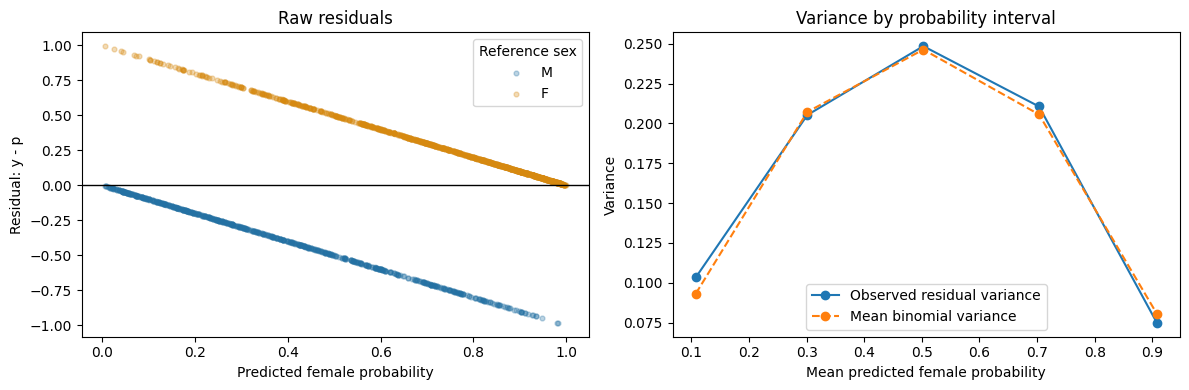

FIVE LARGEST ABSOLUTE RESIDUALS


,Ring,Sex,Wing,Bill,P_female,Predicted_Sex,Residual
845,Z062396,F,160,30.5,0.0058,M,0.9942
403,Z049413,M,178,38.9,0.9827,F,-0.9827
902,Z063154,M,178,38.7,0.9807,F,-0.9807
947,Z023767,F,163,32.0,0.0261,M,0.9739
559,Z049322,F,157,35.1,0.0409,M,0.9591


In [21]:
import matplotlib.pyplot as plt

# Calculate residuals from the existing cross-validation predictions
residual_diagnostics = oof_predictions.copy()

residual_diagnostics["Observed_female"] = (
    residual_diagnostics["Sex"].map({"M": 0, "F": 1})
)

residual_diagnostics["Residual"] = (
    residual_diagnostics["Observed_female"]
    - residual_diagnostics["P_female"]
)

residual_diagnostics["Expected_variance"] = (
    residual_diagnostics["P_female"]
    * (1 - residual_diagnostics["P_female"])
)

residual_diagnostics["Absolute_residual"] = (
    residual_diagnostics["Residual"].abs()
)

# Define fixed probability intervals
residual_diagnostics["Probability_group"] = pd.cut(
    residual_diagnostics["P_female"],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    labels=[
        "0.0-0.2", "0.2-0.4", "0.4-0.6",
        "0.6-0.8", "0.8-1.0"
    ],
    include_lowest=True
)

# Summarize residuals and variance within each interval
residual_summary = (
    residual_diagnostics
    .groupby("Probability_group", observed=True)
    .agg(
        Birds=("Ring", "size"),
        Mean_probability=("P_female", "mean"),
        Female_fraction=("Observed_female", "mean"),
        Mean_residual=("Residual", "mean"),
        Residual_variance=("Residual", "var"),
        Expected_variance=("Expected_variance", "mean")
    )
    .reset_index()
)

display(residual_summary.round(4))

# Plot residuals and their variance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for sex, color in [("M", "#2471A3"), ("F", "#D68910")]:
    subset = residual_diagnostics.loc[
        residual_diagnostics["Sex"].eq(sex)
    ]

    axes[0].scatter(
        subset["P_female"],
        subset["Residual"],
        s=12,
        alpha=0.3,
        color=color,
        label=sex
    )

axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Predicted female probability")
axes[0].set_ylabel("Residual: y - p")
axes[0].set_title("Raw residuals")
axes[0].legend(title="Reference sex")

axes[1].plot(
    residual_summary["Mean_probability"],
    residual_summary["Residual_variance"],
    marker="o",
    label="Observed residual variance"
)

axes[1].plot(
    residual_summary["Mean_probability"],
    residual_summary["Expected_variance"],
    marker="o",
    linestyle="--",
    label="Mean binomial variance"
)

axes[1].set_xlabel("Mean predicted female probability")
axes[1].set_ylabel("Variance")
axes[1].set_title("Variance by probability interval")
axes[1].legend()

plt.tight_layout()
plt.show()

# Inspect five confident classification errors
error_cases = residual_diagnostics.nlargest(
    5, "Absolute_residual"
)

print("FIVE LARGEST ABSOLUTE RESIDUALS")

display(
    error_cases[[
        "Ring", "Sex", "Wing", "Bill",
        "P_female", "Predicted_Sex", "Residual"
    ]].round(4)
)

#### Interpretation of residual diagnostics

The two parallel lines in the residual plot follow directly
from the binary response: residuals equal 1 − p for females
and −p for males. This pattern alone does not indicate
whether the model is adequate.

Mean residuals within the five probability intervals range
from −0.0165 to 0.0089. Predicted female probabilities are
therefore close to observed female proportions at this
grouping level. This coarse check does not establish
calibration for every individual or subgroup.

Residual variance is highest in the 0.4–0.6 interval
(0.2484), close to the mean model-implied variance of 0.2463.
Variance decreases towards the probability extremes.
This nonconstant variance is expected for a Bernoulli response
and is broadly consistent with the logistic model.

Confident classification errors nevertheless occur.
For example, female Z062396 receives a female probability
of 0.0058, while male Z049413 receives a female probability
of 0.9827. These cases demonstrate that morphometric
predictions can be strongly inconsistent with reference sex,
even when grouped predictions appear well calibrated.

### 3.4. Influence of individual observations

Case-deletion sensitivity is examined by omitting each training
bird in turn and refitting the selected model.

Predicted probabilities are compared with the full-training
model on the same set of training feature values. Maximum and
mean absolute probability changes are reported in percentage
points, together with the number of changed classifications.

Coefficient changes are calculated on the original
per-millimetre scale.

These comparisons measure sensitivity to individual observations;
they are not estimates of predictive accuracy.

In [22]:
import numpy as np
from sklearn.base import clone

# Prepare arrays for repeated case-deletion fits
X_influence = X_train[SELECTED_FEATURES].to_numpy()
y_influence = y_train_binary.to_numpy()

# Reference predictions and coefficients from the full-training model
reference_probability = selected_model.predict_proba(
    X_train[SELECTED_FEATURES]
)[:, 1]

reference_class = reference_probability > 0.5

reference_coef = (
    selected_model.named_steps["logistic"].coef_[0]
    / selected_model.named_steps["scaler"].scale_
)

influence_rows = []
coefficient_changes = []

# Temporarily omit each bird and refit the model
for position in range(len(X_influence)):

    keep = np.arange(len(X_influence)) != position

    reduced_model = clone(selected_model)
    reduced_model.fit(X_influence[keep], y_influence[keep])

    reduced_probability = reduced_model.predict_proba(
        X_influence
    )[:, 1]

    probability_change = np.abs(
        reduced_probability - reference_probability
    )

    reduced_coef = (
        reduced_model.named_steps["logistic"].coef_[0]
        / reduced_model.named_steps["scaler"].scale_
    )

    coefficient_changes.append(reduced_coef - reference_coef)

    influence_rows.append({
        "Ring": train_df.iloc[position]["Ring"],
        "Sex": train_df.iloc[position]["Sex"],
        "Max_change_pp": 100 * probability_change.max(),
        "Mean_change_pp": 100 * probability_change.mean(),
        "Changed_predictions": int(
            ((reduced_probability > 0.5) != reference_class).sum()
        )
    })

# Rank observations by their largest effect on probabilities
influence_results = (
    pd.DataFrame(influence_rows)
    .sort_values("Max_change_pp", ascending=False)
    .reset_index(drop=True)
)

print("FIVE MOST INFLUENTIAL OBSERVATIONS")
display(influence_results.head(5).round(4))

# Summarize the largest coefficient changes across all exclusions
coefficient_sensitivity = pd.DataFrame({
    "Predictor": SELECTED_FEATURES,
    "Full_data_coefficient": reference_coef,
    "Largest_absolute_change":
        np.abs(coefficient_changes).max(axis=0)
})

print("\nCOEFFICIENT SENSITIVITY")
display(coefficient_sensitivity.round(6))

FIVE MOST INFLUENTIAL OBSERVATIONS


,Ring,Sex,Max_change_pp,Mean_change_pp,Changed_predictions
0,Z049293,F,1.2586,0.1933,8
1,Z063209,M,1.0550,0.1277,0
2,Z049322,F,1.0303,0.1816,7
3,Z083329,F,0.9807,0.1214,3
4,Z101069,F,0.9263,0.1345,8



COEFFICIENT SENSITIVITY


,Predictor,Full_data_coefficient,Largest_absolute_change
0,Wing,0.245824,0.004139
1,Bill,0.553310,0.007769


#### Interpretation of observation influence

The largest probability change after excluding one bird is
1.26 percentage points, associated with removing Z049293.
The mean absolute change for this exclusion is 0.19 percentage
points, and 8 of 1,704 classifications change.

Across all individual exclusions, the largest coefficient
changes are approximately 1.7% for Wing and 1.4% for Bill.
Both coefficients remain positive.

The fitted model therefore shows limited sensitivity to
the removal of any single training observation.

### 3.5. Learning curves

Learning curves evaluate the selected model using progressively
larger subsets of each cross-validation fitting set.

Five training sizes are examined using the existing
cross-validation splits and random_state=42. Standardization
is fitted within each training subset.

Balanced accuracy is calculated on both the fitting subset
and the corresponding validation subset.

The plot shows mean scores across folds. The shaded band
represents one standard deviation of validation scores,
not a confidence interval.

,Training_birds_per_fold,Training_mean,Training_SD,Validation_mean,Validation_SD
0,136,0.7567,0.0304,0.7552,0.0063
1,340,0.7471,0.0275,0.7558,0.0216
2,681,0.7521,0.0205,0.7550,0.0193
3,1022,0.7539,0.0079,0.7571,0.0225
4,1363,0.7573,0.0063,0.7586,0.0227


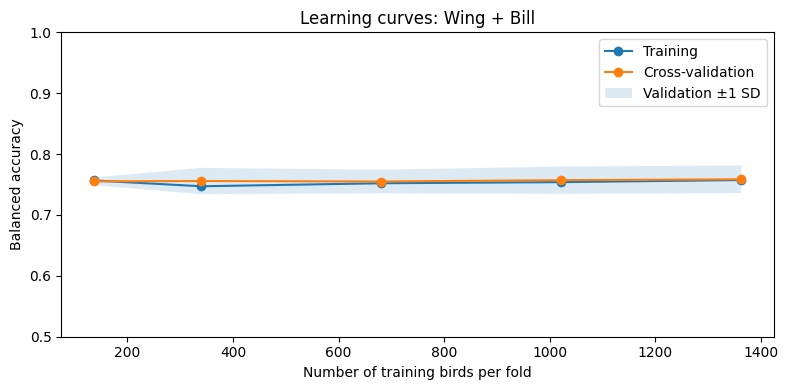

In [23]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Evaluate progressively larger training subsets
learning_sizes, learning_train_scores, learning_validation_scores = (
    learning_curve(
        selected_model,
        X_train[SELECTED_FEATURES],
        y_train_binary,
        cv=cv_splits,
        train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
        scoring="balanced_accuracy",
        shuffle=True,
        random_state=RANDOM_STATE,
        error_score="raise"
    )
)

# Summarize scores across folds
learning_summary = pd.DataFrame({
    "Training_birds_per_fold": learning_sizes,
    "Training_mean": learning_train_scores.mean(axis=1),
    "Training_SD": learning_train_scores.std(axis=1, ddof=1),
    "Validation_mean": learning_validation_scores.mean(axis=1),
    "Validation_SD":
        learning_validation_scores.std(axis=1, ddof=1)
})

display(learning_summary.round(4))

# Plot the learning curves
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    learning_sizes,
    learning_summary["Training_mean"],
    marker="o",
    label="Training"
)

ax.plot(
    learning_sizes,
    learning_summary["Validation_mean"],
    marker="o",
    label="Cross-validation"
)

ax.fill_between(
    learning_sizes,
    learning_summary["Validation_mean"]
        - learning_summary["Validation_SD"],
    learning_summary["Validation_mean"]
        + learning_summary["Validation_SD"],
    alpha=0.15,
    label="Validation ±1 SD"
)

ax.set_xlabel("Number of training birds per fold")
ax.set_ylabel("Balanced accuracy")
ax.set_title("Learning curves: Wing + Bill")
ax.set_ylim(0.5, 1.0)
ax.legend()

plt.tight_layout()
plt.show()

#### Interpretation of the learning curves

Mean validation balanced accuracy remains approximately
75.5–75.9% across the examined training sizes. Increasing
the training subset from 136 to 1,363 birds improves the
mean validation score by approximately 0.34 percentage points.

Training and validation scores are close, providing little
indication of substantial overfitting in this diagnostic.

The learning curve is relatively flat over the examined range.
Additional training observations provide only a small observed
gain, although this does not establish that larger datasets
could never improve performance.

## 4. Final test evaluation

The selected unregularized Wing + Bill model is evaluated
on the frozen test set of 426 individuals.

The model and preprocessing were fitted to the training set.
No model selection or parameter tuning is performed here.

Test accuracy and balanced accuracy are compared with the
majority-class baseline fitted to the training set.

The confusion matrix and recall for each sex describe
the distribution of test errors.

In [24]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Prepare the frozen test data
X_test = test_df[SELECTED_FEATURES].copy()

y_test_binary = test_df["Sex"].map({
    "M": 0,
    "F": 1
}).astype(int)

# Predict using the previously fitted selected model
test_pred_binary = selected_model.predict(X_test)
test_prob_female = selected_model.predict_proba(X_test)[:, 1]

# Fit the majority baseline using training data only
final_baseline = DummyClassifier(strategy="most_frequent")

final_baseline.fit(
    X_train[SELECTED_FEATURES],
    y_train_binary
)

baseline_test_pred = final_baseline.predict(X_test)

# Compare test performance
test_results = pd.DataFrame([
    {
        "Model": "Majority baseline",
        "Accuracy": accuracy_score(
            y_test_binary, baseline_test_pred
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_test_binary, baseline_test_pred
        )
    },
    {
        "Model": "Wing + Bill",
        "Accuracy": accuracy_score(
            y_test_binary, test_pred_binary
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y_test_binary, test_pred_binary
        )
    }
])

display(test_results.round(4))

# Retain individual test predictions
test_predictions = test_df.copy()
test_predictions["P_female"] = test_prob_female

test_predictions["Predicted_Sex"] = pd.Series(
    test_pred_binary,
    index=test_df.index
).map({0: "M", 1: "F"})

test_predictions["Correct"] = (
    test_predictions["Sex"]
    == test_predictions["Predicted_Sex"]
)

# Show the test confusion matrix
test_cm = confusion_matrix(
    y_test_binary,
    test_pred_binary,
    labels=[0, 1]
)

print("\nTEST CONFUSION MATRIX")

display(pd.DataFrame(
    test_cm,
    index=["Actual M", "Actual F"],
    columns=["Predicted M", "Predicted F"]
))

# Summarize test performance by sex
test_sex_summary = pd.DataFrame({
    "Sex": ["M", "F"],
    "Birds": test_cm.sum(axis=1),
    "Correct": test_cm.diagonal(),
    "Errors": test_cm.sum(axis=1) - test_cm.diagonal(),
    "Recall": test_cm.diagonal() / test_cm.sum(axis=1)
})

print("\nTEST PERFORMANCE BY SEX")
display(test_sex_summary.round(4))

,Model,Accuracy,Balanced accuracy
0,Majority baseline,0.5939,0.5000
1,Wing + Bill,0.7371,0.7183



TEST CONFUSION MATRIX


,Predicted M,Predicted F
Actual M,107,66
Actual F,46,207



TEST PERFORMANCE BY SEX


,Sex,Birds,Correct,Errors,Recall
0,M,173,107,66,0.6185
1,F,253,207,46,0.8182


#### Interpretation of the final test results

The selected Wing + Bill model correctly classifies 314 of
426 test birds, achieving 73.7% accuracy and 71.8% balanced
accuracy. It outperforms the majority-class baseline, which
achieves 59.4% accuracy and 50.0% balanced accuracy.

Performance differs between sexes: 81.8% of females and
61.8% of males are correctly classified. The model therefore
has a substantial limitation in identifying males.

Both test metrics are lower than the cross-validation estimates.
The final assessment supports moderate predictive performance,
with important individual errors and unequal recall between sexes.

## 5. Complexity gains, causality, and claim boundary

### 5.1. Does model complexity improve prediction?

Combining wing and bill length improves cross-validation
performance compared with either measurement alone.
Balanced accuracy increases from 72.3% for Wing alone
to 75.9% for Wing + Bill.

Adding Tarsus produces no material improvement. Ridge and
lasso regularization also provide nearly identical scores
to the corresponding unregularized models.

The simpler unregularized Wing + Bill model is therefore
retained. These results show that additional predictors
and tuning do not automatically improve predictive performance.

### 5.2. Why coefficients are not automatically causal

The coefficients describe associations between measurements
and the probability of being female, conditional on the other
predictor.

This observational analysis does not estimate the causal effect
of changing a measurement. A positive coefficient does not
mean that increasing wing or bill length would change a bird's sex.

Coefficient values also depend on the predictors included
and their relationships. They should therefore be interpreted
as components of a predictive rule, rather than automatic
measures of causal influence or biological importance.

### 5.3. Claim boundary and conclusion

Wing and bill length contain useful information for predicting
sex in the analysed adult Red Knot dataset. However, test accuracy
of 73.7% does not support near-certain individual sex assignment.
Male recall is particularly limited, and confident errors occur.

The individual-level random split evaluates predictions within
the same sampling framework. It does not establish transferability
to juveniles, other populations or subspecies, or new sampling
locations and periods.

The main conclusion is that a simple, interpretable morphometric
model improves on the naive baseline, while retaining substantial
and clearly identified limitations.